# Gaussian splatting fundamentals: from one 3D Gaussian to a differentiable renderer

3D Gaussian Splatting (3DGS, Kerbl et al. 2023) represents a scene as a cloud of millions of
anisotropic 3D Gaussians and renders it by **projecting** each Gaussian to a 2D ellipse
and **alpha-compositing** the ellipses front to back. Every step is differentiable, so all
Gaussian parameters can be fitted to photos by gradient descent, and rendering runs at
hundreds of frames per second on a laptop GPU. That speed is why 3DGS is used in robotics
for simulation, digital twins and dense mapping.

**What this notebook does**
1. Builds one 3D Gaussian from a scale vector and a quaternion.
2. Projects it to the image with the EWA (Jacobian) approximation, written in numpy, and
   checks the result against gsplat's CUDA kernel and a Monte Carlo ground truth.
3. Re-implements front-to-back alpha compositing in numpy and checks that it reproduces
   gsplat's rasteriser pixel for pixel.
4. Shows how spherical harmonics (SH) give a Gaussian a view-dependent colour.
5. Uses the differentiable rasteriser to fit a photo with 2k and 20k Gaussians.

**What you'll learn**: the 3DGS parameterisation (mean, log-scale, quaternion, logit-opacity,
SH colour), the projected-covariance equation, the compositing equation, and what
"differentiable rasterisation" means in practice.

**Prerequisites**: pinhole camera model and world-to-camera transforms (project 01),
basic PyTorch autograd. Data: `make data-11_gaussian_splatting` (one bonsai photo is used).
Runtime: under a minute on an RTX 5060 Laptop GPU (8 GB).

## Setup

`splatkit.py` (in `projects/11_gaussian_splatting/scripts/`) is this project's compact
trainer on gsplat's public API. Here we mostly use gsplat's low-level functions directly,
so each stage of the pipeline can be checked on its own.

In [1]:
# --- Setup: imports, device, repo-relative paths, plot style ---
# gsplat's CUDA kernels were JIT-compiled once for this GPU (sm_120); importing is instant now.
import sys
import time

import gsplat
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gsplat import fully_fused_projection, rasterization, spherical_harmonics
from matplotlib.patches import Ellipse

from cvlab import viz
from cvlab.device import setup, track_vram
from cvlab.geometry import invert_T, look_at, project_points
from cvlab.io import data_dir, project_dir, read_image, repo_root

PROJECT = "11_gaussian_splatting"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import splatkit as S  # noqa: E402

device = setup(seed=0)
viz.set_style()
SCENE_DIR = data_dir("mipnerf360", "bonsai")
print("gsplat", gsplat.__version__, "| scene:", SCENE_DIR.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
gsplat 1.5.3 | scene: data/mipnerf360/bonsai


## 1. One 3D Gaussian

A Gaussian has a mean $\boldsymbol\mu\in\mathbb R^3$ and a covariance $\Sigma$. Gradient
descent on a raw $3\times3$ matrix would quickly make it non positive-definite, so 3DGS
stores a **scale** vector $\mathbf s$ and a unit **quaternion** $\mathbf q$ and builds

$$\Sigma = R(\mathbf q)\,S\,S^\top R(\mathbf q)^\top,\qquad S=\operatorname{diag}(\mathbf s).$$

This is positive semi-definite by construction. The eigenvalues of $\Sigma$ are $s_i^2$ and
the eigenvectors are the columns of $R$. The optimiser works on unconstrained raw values:
$\log \mathbf s$, an unnormalised $\mathbf q$ and $\operatorname{logit}(o)$ for the opacity
$o\in(0,1)$. The density that is splatted is
$G(\mathbf x)=o\,\exp\!\big(-\tfrac12(\mathbf x-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x-\boldsymbol\mu)\big)$.

Sigma =
 [[0.05581 0.00762 0.04129]
 [0.00762 0.01004 0.01074]
 [0.04129 0.01074 0.03505]]
sqrt(eigenvalues): [0.03 0.1  0.3 ] -> the scales, sorted
raw parameters: log-scales [-1.204 -2.303 -3.507] | logit(0.8) = 1.386


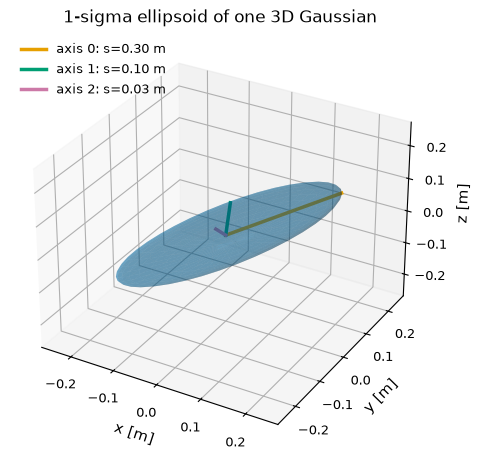

In [2]:
# --- Build a covariance from scale + rotation and draw its 1-sigma ellipsoid ---
# Scales are the standard deviations along the Gaussian's own axes (scene units, here metres).
scales = np.array([0.30, 0.10, 0.03])
quat = np.array([0.92, 0.20, -0.30, 0.15])  # wxyz (gsplat order), normalised inside
Sigma = S.covariance_from_scale_rot(scales, quat)
evals, evecs = np.linalg.eigh(Sigma)
print("Sigma =\n", Sigma.round(5))
print("sqrt(eigenvalues):", np.sqrt(evals).round(4), "-> the scales, sorted")
print("raw parameters: log-scales", np.log(scales).round(3), "| logit(0.8) =",
      round(float(np.log(0.8 / 0.2)), 3))

# 1-sigma surface: map the unit sphere through R S, i.e. x = mu + R S u.
u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
sphere = np.stack([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)], -1)  # (40,20,3)
R = S.quat_to_rotmat_wxyz(quat)
ell = sphere @ (R @ np.diag(scales)).T
fig = plt.figure(figsize=(5.5, 4.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(*ell.transpose(2, 0, 1), color=viz.color(0, unit=True), alpha=0.35, lw=0)
for k in range(3):  # principal axes (columns of R) scaled by s_k
    ax.plot(*np.stack([np.zeros(3), R[:, k] * scales[k]]).T, color=viz.color(k + 1, unit=True),
            lw=2.5, label=f"axis {k}: s={scales[k]:.2f} m")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
viz.set_axes_equal(ax)
ax.legend(loc="upper left")
ax.set_title("1-sigma ellipsoid of one 3D Gaussian")
plt.show()

## 2. Projection to the image: EWA splatting

A perspective projection does not map a Gaussian to a Gaussian, so 3DGS linearises it at the
mean (Zwicker et al., *EWA splatting*, 2002). With the world-to-camera rotation $W$ and the
mean in camera coordinates $(x, y, z)$:

$$\Sigma_{2D} = J\,W\,\Sigma\,W^\top J^\top,\qquad
J=\begin{bmatrix} f_x/z & 0 & -f_x x/z^2\\ 0 & f_y/z & -f_y y/z^2\end{bmatrix}.$$

gsplat also adds $0.3\,I$ to $\Sigma_{2D}$ (a low-pass "dilation" so that every splat covers
at least about one pixel) and stores the inverse, the **conic** $(a,b,c)$. Below, the
numpy equation, gsplat's fused CUDA kernel and a brute-force Monte Carlo estimate (sample
3D points, project each one exactly) are compared.

In [3]:
# --- EWA projection in numpy vs gsplat's CUDA kernel vs Monte Carlo ---
# Camera 2.8 m away looking at the Gaussian; 640x480 image, f = 600 px (OpenCV axes).
K = np.array([[600.0, 0, 320], [0, 600.0, 240], [0, 0, 1]])
W_IMG, H_IMG = 640, 480
w2c = invert_T(look_at([0.8, -2.5, 0.9], [0.0, 0.0, 0.0]))
mean = np.zeros(3)
m2d, cov2d = S.project_covariance(mean, Sigma, w2c, K)


def t32(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32, device=device)


radii, means2d, depths, conics, _ = fully_fused_projection(
    t32(mean)[None], None, t32(quat)[None], t32(scales)[None], t32(w2c)[None], t32(K)[None],
    W_IMG, H_IMG, eps2d=0.3)  # shapes: (C=1, N=1, ...)
a, b, c = conics[0, 0].tolist()
cov_gs = np.linalg.inv(np.array([[a, b], [b, c]])) - 0.3 * np.eye(2)  # undo the dilation

rng = np.random.default_rng(0)
X = rng.multivariate_normal(mean, Sigma, size=50_000)
uv, _ = project_points(X, K, w2c)  # exact perspective projection of every sample
cov_mc = np.cov(uv.T)
checks = pd.DataFrame({
    "source": ["numpy EWA", "gsplat kernel", "Monte Carlo (50k samples)"],
    "mean u [px]": [m2d[0], means2d[0, 0, 0].item(), uv[:, 0].mean()],
    "mean v [px]": [m2d[1], means2d[0, 0, 1].item(), uv[:, 1].mean()],
    "var u [px^2]": [cov2d[0, 0], cov_gs[0, 0], cov_mc[0, 0]],
    "cov uv [px^2]": [cov2d[0, 1], cov_gs[0, 1], cov_mc[0, 1]],
    "var v [px^2]": [cov2d[1, 1], cov_gs[1, 1], cov_mc[1, 1]],
}).round(3)
ewa_err = float(np.abs(cov_gs - cov2d).max() / np.abs(cov2d).max())
print(f"gsplat vs numpy: max relative difference {ewa_err:.1e}; "
      f"3-sigma radius used for tiling: {radii[0, 0].tolist()} px")
checks

gsplat vs numpy: max relative difference 5.4e-07; 3-sigma radius used for tiling: [171, 127] px


,source,mean u [px],mean v [px],var u [px^2],cov uv [px^2],var v [px^2]
0,numpy EWA,320.000,240.00,2617.538,-1776.604,1447.308
1,gsplat kernel,320.000,240.00,2617.539,-1776.605,1447.308
2,Monte Carlo (50k samples),321.469,239.34,2654.988,-1795.435,1457.579


The three agree. The small Monte Carlo difference is the linearisation error of EWA, which
grows for Gaussians that are large relative to their distance from the camera. The plot
shows the samples and the 1/2/3-sigma ellipses of $\Sigma_{2D}$.

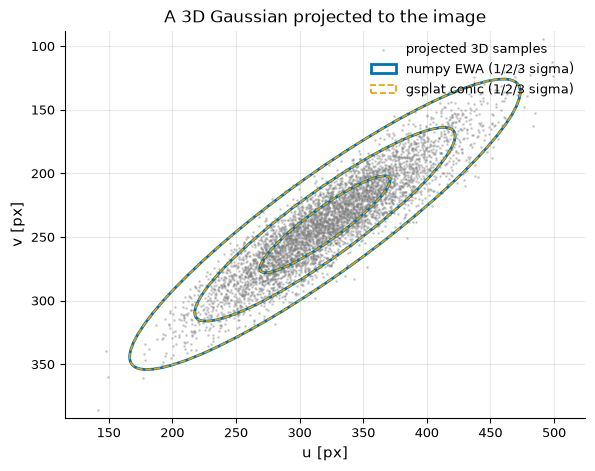

In [4]:
# --- Plot projected samples with the EWA ellipses ---
# Ellipse axes come from the eigen-decomposition of the 2x2 covariance (k-sigma: k*sqrt(eig)).
def add_cov_ellipse(ax, mu, cov, k, **kw):
    ev, V = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
    ax.add_patch(Ellipse(mu, 2 * k * np.sqrt(ev[1]), 2 * k * np.sqrt(ev[0]), angle=ang,
                         fill=False, **kw))


fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.scatter(uv[::10, 0], uv[::10, 1], s=1, alpha=0.3, color="0.5", label="projected 3D samples")
for k in (1, 2, 3):
    add_cov_ellipse(ax, m2d, cov2d, k, color=viz.color(0, unit=True), lw=2,
                    label="numpy EWA (1/2/3 sigma)" if k == 1 else None)
    add_cov_ellipse(ax, means2d[0, 0].cpu().numpy(), cov_gs, k, color=viz.color(1, unit=True),
                    lw=1.2, ls="--", label="gsplat conic (1/2/3 sigma)" if k == 1 else None)
ax.set_xlim(m2d[0] - 4 * np.sqrt(cov2d[0, 0]), m2d[0] + 4 * np.sqrt(cov2d[0, 0]))
ax.set_ylim(m2d[1] + 4 * np.sqrt(cov2d[1, 1]), m2d[1] - 4 * np.sqrt(cov2d[1, 1]))  # v down
ax.set_aspect("equal")
ax.set_xlabel("u [px]")
ax.set_ylabel("v [px]")
ax.set_title("A 3D Gaussian projected to the image")
ax.legend(loc="upper right")
plt.show()

## 3. Alpha compositing, re-implemented

After projection, the pixels of each 16x16 tile are shaded by the Gaussians that overlap the
tile, **sorted by depth**. With $\alpha_i = \min(0.999,\ o_i\,e^{-\frac12 \mathbf d^\top
\Sigma_{2D,i}^{-1}\mathbf d})$ for the pixel offset $\mathbf d$ from the projected mean:

$$C = \sum_i \mathbf c_i\,\alpha_i\,T_i,\qquad T_i=\prod_{j<i}(1-\alpha_j),\qquad
\hat D = \frac{\sum_i z_i\,\alpha_i T_i}{\sum_i \alpha_i T_i}.$$

$T_i$ is the transmittance (how much light still gets through). gsplat skips $\alpha<1/255$
and stops a pixel once $T$ would drop below $10^{-4}$. The numpy loop below follows these
rules and should match the CUDA rasteriser up to float rounding. $\hat D$ (`render_mode="RGB+ED"`,
"expected depth") is how a splat model gives depth maps for robotics.

max |numpy - gsplat|: RGB 1.3e-07, alpha 1.5e-07


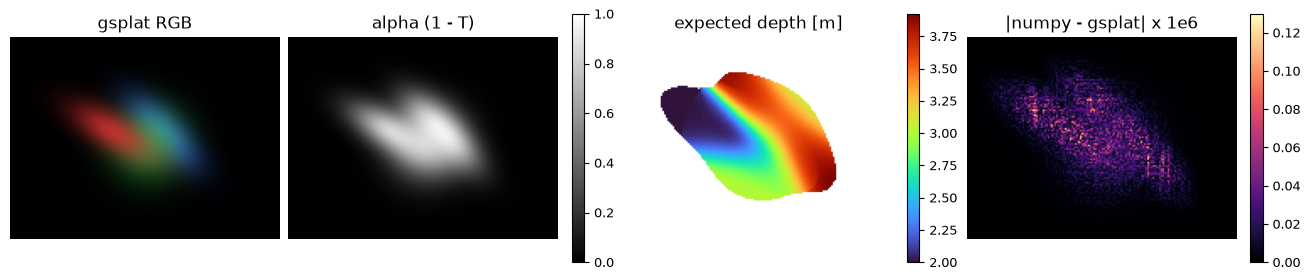

In [5]:
# --- Render three overlapping Gaussians with gsplat and with a numpy reference ---
# Camera at the origin looking down +z (identity world-to-camera); 160x120 px, f = 150 px.
Wt, Ht = 160, 120
Kt = np.array([[150.0, 0, Wt / 2], [0, 150.0, Ht / 2], [0, 0, 1]])
means3 = np.array([[-0.25, -0.05, 2.0], [0.05, 0.05, 3.0], [0.30, -0.10, 4.0]])  # metres
scales3 = np.array([[0.25, 0.10, 0.05], [0.30, 0.30, 0.05], [0.20, 0.50, 0.05]])
quats3 = np.array([[0.97, 0, 0, 0.26], [1.0, 0, 0, 0], [0.92, 0, 0, -0.38]])
cols3 = np.array([[0.9, 0.2, 0.2], [0.2, 0.8, 0.3], [0.2, 0.3, 0.9]])
opac3 = np.array([0.8, 0.7, 0.9])
args = [t32(means3), t32(quats3), t32(scales3), t32(opac3), t32(cols3), t32(np.eye(4))[None],
        t32(Kt)[None], Wt, Ht]
out, alpha, meta = rasterization(*args, render_mode="RGB+ED", packed=False)
rgb_gs, depth_gs = out[0, ..., :3].cpu().numpy(), out[0, ..., 3].cpu().numpy()
alpha_gs = alpha[0, ..., 0].cpu().numpy()


def composite_numpy(m2d, conic, z, cols, opac, W, H):
    # Front-to-back compositing with gsplat's rules; pixel centres at (j + 0.5, i + 0.5).
    py, px = np.mgrid[0:H, 0:W] + 0.5
    C, T, Dw = np.zeros((H, W, 3)), np.ones((H, W)), np.zeros((H, W))
    done = np.zeros((H, W), bool)
    for i in np.argsort(z):
        dx, dy = m2d[i, 0] - px, m2d[i, 1] - py
        sig = 0.5 * (conic[i, 0] * dx**2 + conic[i, 2] * dy**2) + conic[i, 1] * dx * dy
        a = np.minimum(0.999, opac[i] * np.exp(-sig))
        a[(sig < 0) | (a < 1 / 255) | done] = 0.0
        next_T = T * (1 - a)
        stop = next_T <= 1e-4
        a[stop], done = 0.0, done | stop
        C += (a * T)[..., None] * cols[i]
        Dw += a * T * z[i]
        T = np.where(a > 0, next_T, T)
    acc = 1 - T
    return C, acc, Dw / np.maximum(acc, 1e-10)


m2d3, con3, z3 = (meta["means2d"][0].cpu().numpy(), meta["conics"][0].cpu().numpy(),
                  meta["depths"][0].cpu().numpy())
rgb_np, alpha_np, depth_np = composite_numpy(m2d3, con3, z3, cols3, opac3, Wt, Ht)
comp_err = float(np.abs(rgb_np - rgb_gs).max())
print(f"max |numpy - gsplat|: RGB {comp_err:.1e}, alpha {np.abs(alpha_np - alpha_gs).max():.1e}")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
axes[0].imshow(rgb_gs.clip(0, 1))
axes[0].set_title("gsplat RGB")
im = axes[1].imshow(alpha_gs, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("alpha (1 - T)")
fig.colorbar(im, ax=axes[1], fraction=0.046)
dm = np.where(alpha_gs > 0.05, depth_gs, np.nan)
im = axes[2].imshow(dm, cmap="turbo")
axes[2].set_title("expected depth [m]")
fig.colorbar(im, ax=axes[2], fraction=0.046)
im = axes[3].imshow(np.abs(rgb_np - rgb_gs).max(-1) * 1e6, cmap="magma")
axes[3].set_title("|numpy - gsplat| x 1e6")
fig.colorbar(im, ax=axes[3], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.show()

Note the purple-ish mix where the red Gaussian (nearest, $z=2$ m) overlaps the others, and
that the expected depth is a blend of the depths: at a boundary between two surfaces
$\hat D$ falls in between them. Dense maps built from splat depth renders need an
opacity/alpha threshold for this reason.

## 4. View-dependent colour with spherical harmonics

Shiny surfaces change colour with the viewing direction $\mathbf d$. 3DGS stores per
Gaussian and per colour channel the coefficients $k_{\ell m}$ of real spherical harmonics up
to degree 3 (16 coefficients x 3 channels = 48 numbers):

$$\mathbf c(\mathbf d) = \max\Big(0,\ \tfrac12 + \sum_{\ell=0}^{3}\sum_{m=-\ell}^{\ell} k_{\ell m}\,Y_{\ell m}(\mathbf d)\Big).$$

The $\ell=0$ term $Y_{00}=0.2821$ is the view-independent base colour (`sh0`). The higher
bands (`shN`) start at zero, and training turns them on one degree every 1000 steps.

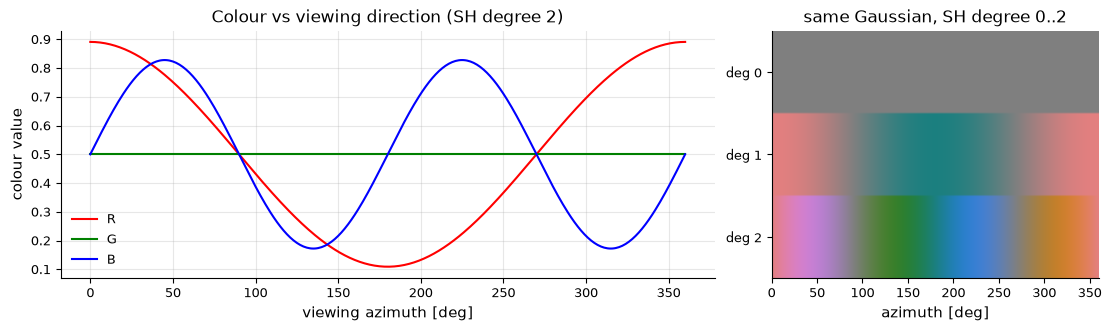

In [6]:
# --- Evaluate SH colour for viewing directions around a Gaussian ---
# Grey base colour + a degree-1 red term along x and a degree-2 blue term.
# gsplat's degree-1 basis order is (-C1*y, C1*z, -C1*x), so index 3 multiplies -x.
coeffs = torch.zeros(1, 16, 3, device=device)
coeffs[0, 0] = S.rgb_to_sh(torch.full((3,), 0.5, device=device))
coeffs[0, 3, 0] = -0.8  # red increases towards +x
coeffs[0, 4, 2] = 0.6   # first degree-2 basis (~xy): blue lobes on the diagonals
az = torch.linspace(0, 2 * np.pi, 361, device=device)
dirs = torch.stack([torch.cos(az), torch.sin(az), torch.zeros_like(az)], -1)  # unit vectors
rgb_by_deg = {d: (spherical_harmonics(d, dirs, coeffs.expand(361, 16, 3)) + 0.5).clamp(0, 1)
              .cpu().numpy() for d in (0, 1, 2)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2, 1]})
for ch, name in enumerate("RGB"):
    axes[0].plot(np.degrees(az.cpu()), rgb_by_deg[2][:, ch], color="rgb"[ch], label=name)
axes[0].set_xlabel("viewing azimuth [deg]")
axes[0].set_ylabel("colour value")
axes[0].set_title("Colour vs viewing direction (SH degree 2)")
axes[0].legend()
strip = np.stack([rgb_by_deg[d] for d in (0, 1, 2)])  # (3, 361, 3)
axes[1].imshow(np.repeat(strip, 30, axis=0), aspect="auto", extent=[0, 360, 3, 0])
axes[1].set_yticks([0.5, 1.5, 2.5], ["deg 0", "deg 1", "deg 2"])
axes[1].set_xlabel("azimuth [deg]")
axes[1].set_title("same Gaussian, SH degree 0..2")
axes[1].grid(False)
plt.show()

## 5. Differentiable rasterisation: fitting a photo

gsplat's rasteriser has a hand-written backward pass, so
$\partial\mathcal L/\partial\{\boldsymbol\mu,\log\mathbf s,\mathbf q,\operatorname{logit} o,\mathbf c\}$
is available for every Gaussian. A good first exercise (gsplat's own "image fitting"
example) is to put random Gaussians on a thin slab in front of a camera and fit **one photo**.
There is no 3D supervision here, only the 2D reconstruction loss
$\mathcal L = \lVert \hat I - I\rVert_1$, and Adam moves, stretches, rotates and recolours
the splats until the render matches.

We fit a 400x267 bonsai photo with 2,000 and with 20,000 Gaussians (1,000 Adam steps each).

In [7]:
# --- Image fitting with N Gaussians: one optimisation loop ---
# Gaussians start uniform over the visible slab at z ~ 2 m with radius ~ grid spacing,
# grey colour and opacity 0.5; colours are plain RGB here (sh_degree=None).
img_path = sorted((SCENE_DIR / "images_4").glob("*.png"))[1]
target_np = read_image(img_path, max_side=400)
target = torch.from_numpy(target_np).float().div(255).to(device)  # (H, W, 3) in [0, 1]
Hf, Wf = target.shape[:2]
f_fit = float(0.5 * Wf / np.tan(np.radians(30)))  # 60 deg horizontal FOV (python float)
K_fit = t32([[f_fit, 0, Wf / 2], [0, f_fit, Hf / 2], [0, 0, 1]])[None]
VIEW = t32(np.eye(4))[None]
Z0 = 2.0


def fit_image(n, steps=1000, seed=0, snapshots=(0, 50, 200, 1000)):
    g = torch.Generator(device=device).manual_seed(seed)
    # half-extent of the slab [m]; float32 explicitly, gsplat kernels reject float64
    half = torch.tensor([Z0 * Wf / (2 * f_fit), Z0 * Hf / (2 * f_fit), 0.05], device=device,
                        dtype=torch.float32)
    params = {
        "means": (torch.rand(n, 3, generator=g, device=device) * 2 - 1) * half
        + torch.tensor([0, 0, Z0], device=device),
        "scales": torch.full((n, 3), float(np.log(2 * half[0].item() / np.sqrt(n))),
                             device=device),
        "quats": torch.rand(n, 4, generator=g, device=device),
        "opacities": torch.zeros(n, device=device),  # sigmoid(0) = 0.5
        "colors": torch.zeros(n, 3, device=device),  # sigmoid(0) = 0.5 grey
    }
    for p in params.values():
        p.requires_grad_(True)
    lrs = {"means": 2e-3, "scales": 1e-2, "quats": 1e-2, "opacities": 5e-2, "colors": 5e-2}
    opt = torch.optim.Adam([{"params": [params[k]], "lr": lr} for k, lr in lrs.items()])
    curve, snaps = [], {}
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    with track_vram() as mem:
        for step in range(steps + 1):
            out, _, _ = rasterization(params["means"], params["quats"],
                                      params["scales"].exp(), params["opacities"].sigmoid(),
                                      params["colors"].sigmoid(), VIEW, K_fit, Wf, Hf)
            pred = out[0]
            if step in snapshots:
                snaps[step] = pred.detach().clamp(0, 1).cpu().numpy()
            mse = ((pred.detach() - target) ** 2).mean().item() if step % 10 == 0 else None
            if mse is not None:
                curve.append((step, -10 * np.log10(mse)))
            if step == steps:
                break
            loss = (pred - target).abs().mean()  # L1
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
    torch.cuda.synchronize()
    return {"n": n, "curve": np.array(curve), "snaps": snaps,
            "time_s": time.perf_counter() - t0, "peak_mb": mem.peak_mb}


fits = {n: fit_image(n) for n in (2_000, 20_000)}
for n, r in fits.items():
    print(f"{n:>6} Gaussians: PSNR {r['curve'][-1, 1]:.2f} dB after 1000 steps "
          f"| {r['time_s']:.1f} s | peak VRAM {r['peak_mb']:.0f} MiB")

  2000 Gaussians: PSNR 29.29 dB after 1000 steps | 1.3 s | peak VRAM 10 MiB
 20000 Gaussians: PSNR 41.53 dB after 1000 steps | 1.7 s | peak VRAM 15 MiB


## Results

The progression grid shows the 20k-Gaussian fit after 0, 50, 200 and 1000 steps. The curve
compares the two Gaussian budgets: with a fixed budget, fine detail (leaves, the wooden
table texture) is limited by how many splats are available. That is why full 3DGS
**adds** Gaussians during training (adaptive density control, notebook 02).

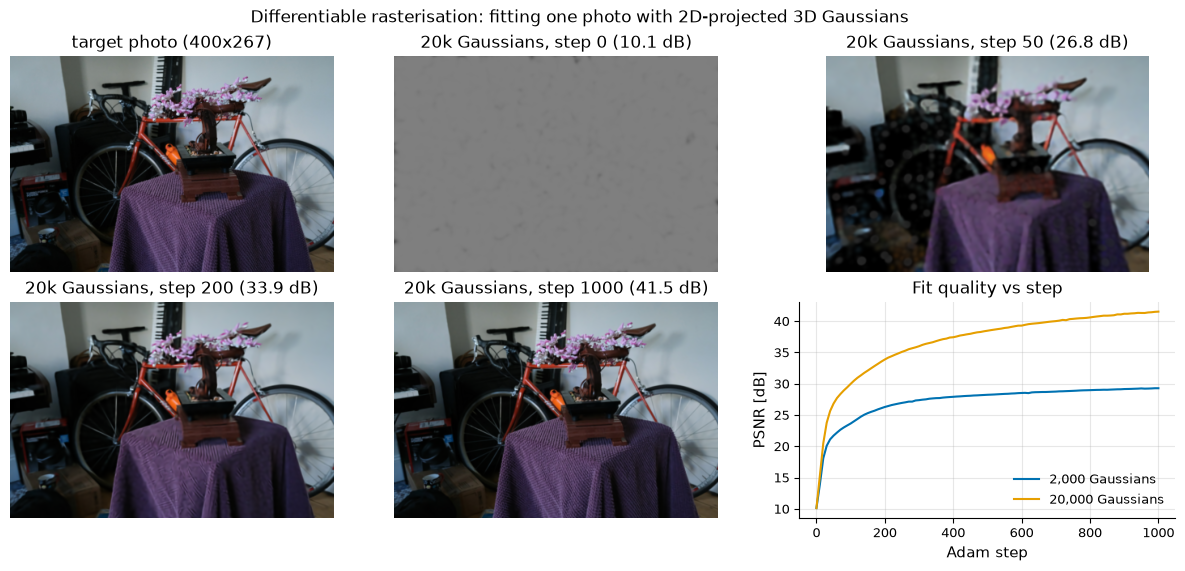

In [8]:
# --- Figure: fitting progression + PSNR curves (saved for the README) ---
r = fits[20_000]
steps_show = sorted(r["snaps"])
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
axes[0, 0].imshow(target_np)
axes[0, 0].set_title("target photo (400x267)")
for ax, s in zip(axes.flat[1:5], steps_show, strict=True):
    ax.imshow(r["snaps"][s])
    psnr_s = r["curve"][r["curve"][:, 0] == s][0, 1]
    ax.set_title(f"20k Gaussians, step {s} ({psnr_s:.1f} dB)")
for ax in axes.flat[:5]:
    ax.axis("off")
ax = axes[1, 2]
for i, (n, rr) in enumerate(fits.items()):
    ax.plot(rr["curve"][:, 0], rr["curve"][:, 1], color=viz.color(i, unit=True),
            label=f"{n:,} Gaussians")
ax.set_xlabel("Adam step")
ax.set_ylabel("PSNR [dB]")
ax.set_title("Fit quality vs step")
ax.legend()
fig.suptitle("Differentiable rasterisation: fitting one photo with 2D-projected 3D Gaussians")
viz.savefig(fig, PROJECT, "image_fitting")
plt.show()

The table collects every number measured in this notebook: the two correctness checks
against the CUDA kernels and the two image-fitting runs (final PSNR, wall time including
the per-step render, and peak VRAM).

In [9]:
# --- Summary table of the measured numbers ---
# Correctness checks (relative/absolute errors) and the two fitting runs on the RTX 5060 GPU.
summary = pd.DataFrame([
    {"experiment": "EWA covariance: gsplat vs numpy", "value": f"{ewa_err:.1e}",
     "unit": "max relative difference"},
    {"experiment": "compositing: gsplat vs numpy", "value": f"{comp_err:.1e}",
     "unit": "max abs RGB difference"},
    *[{"experiment": f"image fit, {n:,} Gaussians, 1000 steps",
       "value": f"{rr['curve'][-1, 1]:.2f} dB | {rr['time_s']:.1f} s | {rr['peak_mb']:.0f} MiB",
       "unit": "PSNR | wall time | peak VRAM"} for n, rr in fits.items()],
])
summary

,experiment,value,unit
0,EWA covariance: gsplat vs numpy,5.4e-07,max relative difference
1,compositing: gsplat vs numpy,1.3e-07,max abs RGB difference
2,"image fit, 2,000 Gaussians, 1000 steps",29.29 dB | 1.3 s | 10 MiB,PSNR | wall time | peak VRAM
3,"image fit, 20,000 Gaussians, 1000 steps",41.53 dB | 1.7 s | 15 MiB,PSNR | wall time | peak VRAM


**Takeaways**

- The covariance factorisation $\Sigma=RSS^\top R^\top$ keeps every Gaussian valid while it
  is optimised with plain Adam on unconstrained raw parameters.
- The EWA equation reproduces gsplat's projected covariance to float precision, and its
  linearisation error against exact Monte Carlo projection is small for Gaussians that are
  small relative to their depth.
- A 20-line numpy loop reproduces the CUDA rasteriser's front-to-back compositing
  (differences at the 1e-6 level). The speed comes from tiling, sorting and fused kernels,
  not from a different equation.
- With a fixed budget, PSNR is limited by the number of Gaussians (see the table: 10x more
  Gaussians gives a clearly higher PSNR in the same number of steps). Scene-scale training
  therefore grows and prunes the set of Gaussians during optimisation.

## Exercises

Solutions: `projects/11_gaussian_splatting/solutions/ex01_fundamentals.py`.

**Exercise 1: perspective stretches splats.** Take an *isotropic* Gaussian (all scales
0.05 m) at depth 2 m and move it from the image centre towards the right image border
(x from 0 to 1.5 m). Plot the ratio of the major to minor axis of $\Sigma_{2D}$ against the
horizontal pixel position, and explain the trend with the third column of $J$.

In [10]:
# --- Exercise 1: anisotropy of the projected covariance across the image ---
# TODO: loop over x positions, call S.project_covariance(mean, cov, np.eye(4), K),
# compute sqrt(max_eig / min_eig) of the 2x2 covariance and plot it against u [px].

**Exercise 2: loss function.** Refit the 20k-Gaussian image with the 3DGS loss
$0.8\,\mathcal L_1 + 0.2\,(1-\mathrm{SSIM})$ (`S.ssim` expects `(B, C, H, W)` tensors) and
compare PSNR and SSIM with the pure L1 fit. Which metric improves, and why?

In [11]:
# --- Exercise 2: L1 vs L1 + D-SSIM for image fitting ---
# TODO: copy fit_image, add a `ssim_lambda` argument, and compare final PSNR / SSIM.

**Exercise 3: rate-distortion.** Fit with 500, 2k, 8k and 32k Gaussians and plot final PSNR
against the number of Gaussians (log x-axis). Roughly how many dB do you gain per doubling?

In [12]:
# --- Exercise 3: PSNR vs number of Gaussians ---
# TODO: call fit_image(n) for n in [500, 2000, 8000, 32000] and plot curve[-1, 1] vs n.